# Bài 2 (Trang 15-17) - Dữ liệu Titanic
## Câu 5: Thống kê số người đi cùng (sibsp, parch) và khảo sát sự liên quan với khả năng sống sót

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

df = pd.read_csv("../Dataset/titanic.csv")

### Câu 5: Thống kê số người đi cùng (sibsp, parch) và khảo sát sự liên quan với khả năng sống sót

In [3]:
df["relatives"] = df["sibsp"] + df["parch"]
df["not_alone"] = (df["relatives"] > 0).astype(int)  # 1: đi cùng người thân, 0: đi một mình

In [4]:
print("Số người đi một mình:", (df["not_alone"] == 0).sum())
print("Số người đi cùng người thân:", (df["not_alone"] == 1).sum())
df["relatives"].value_counts().sort_index()

Số người đi một mình: 790
Số người đi cùng người thân: 519


relatives
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11
Name: count, dtype: int64

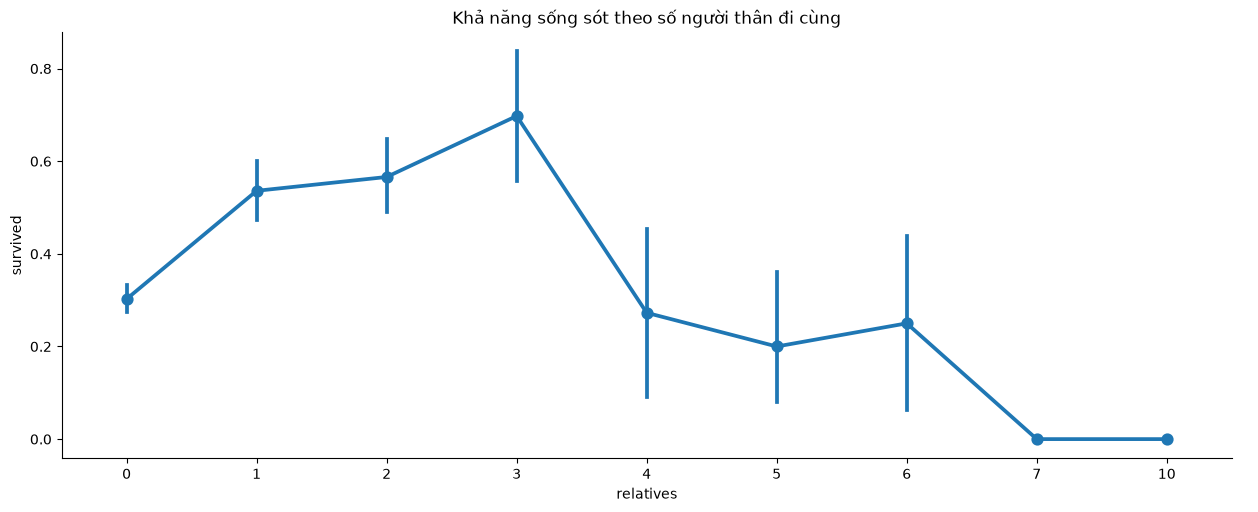

In [5]:
sns.catplot(x="relatives", y="survived", data=df, kind="point", aspect=2.5)
plt.title("Khả năng sống sót theo số người thân đi cùng")
plt.show()

In [6]:
df.groupby("relatives")["survived"].agg(["count", "mean"]).round(3)

,count,mean
relatives,,
0,790,0.303
1,235,0.536
2,159,0.566
3,43,0.698
4,22,0.273
5,25,0.200
6,16,0.250
7,8,0.000
10,11,0.000


### Nhận xét
- Số người đi một mình là **790**, đi cùng người thân là **519**.
- Người có 1-3 người thân đi cùng có tỷ lệ sống sót cao nhất (53-70%); người đi một mình chỉ ~30%.
- Người có từ 4 người thân trở lên có tỷ lệ sống thấp, nhóm 7 và 10 người thân không ai sống sót.